# Analysis: human vs machine

Uses the saved predictions to compare the models with human listeners:

1. Layer vs emotion classification (macro-F1)
2. Layer vs agreement with human listeners (Spearman ρ)
3. Per-clip human agreement vs model confidence
4. Confusion patterns
5. Effect of expression intensity
6. Robustness checks and case-study selection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

meta    = pd.read_csv("../results/metadata.csv")
preds   = pd.read_csv("../results/predictions.csv")
summary = pd.read_csv("../results/classifier_summary.csv", header=[0, 1], index_col=[0, 1])

# attach human agreement + intensity to every prediction row
preds = preds.merge(meta[["filename", "human_agreement", "intensity", "actor"]], on="filename")
print(preds.shape)   # expect (38880, ...)

(38880, 10)


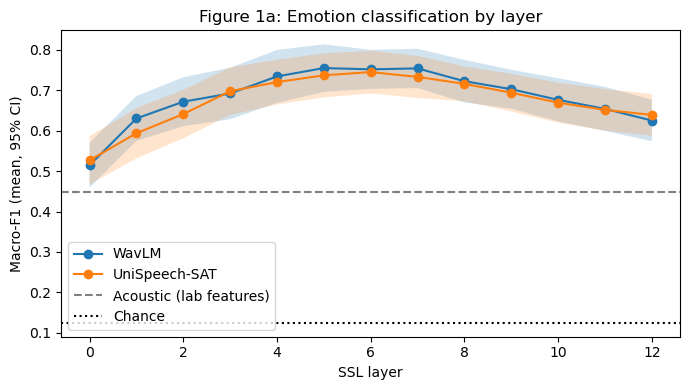

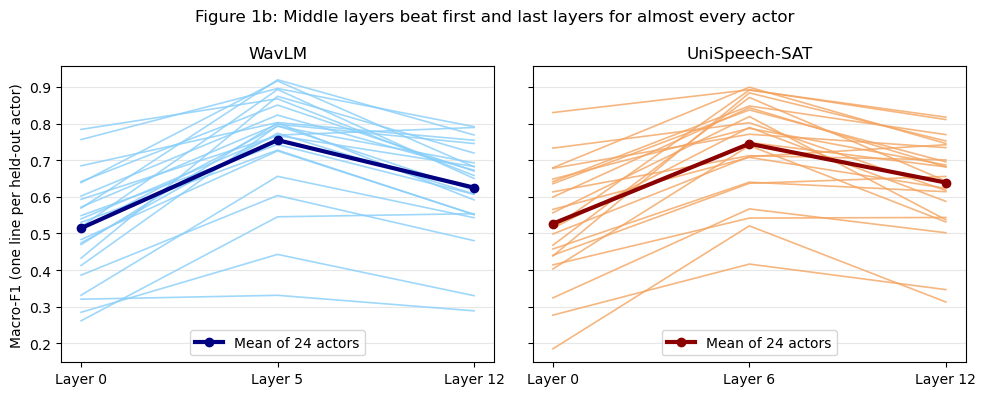

In [2]:
# comparing effectiveness of each layer for the 2 SSL models
# the grrey line shows the  same overall performance of the basic acoustic feature
# baseline as it has no seperate layers like the SSL models.

from sklearn.metrics import f1_score

# per-actor macro-F1 for every system/layer (same predictions as before)
actor_f1 = (preds.groupby(["system", "layer", "actor"])
                 .apply(lambda g: f1_score(g.emotion, g.pred, average="macro"))
                 .rename("f1").reset_index())

# ---- Figure 1a: mean macro-F1 per layer with 95% CI of the mean ----
plt.figure(figsize=(7, 4))
for system, label in [("wavlm", "WavLM"), ("unispeechsat", "UniSpeech-SAT")]:
    g = actor_f1[actor_f1.system == system].groupby("layer").f1
    mean, ci = g.mean(), 1.96 * g.std() / np.sqrt(24)
    plt.plot(mean.index, mean, marker="o", label=label)
    plt.fill_between(mean.index, mean - ci, mean + ci, alpha=0.2)

ac = actor_f1[actor_f1.system == "acoustic"].f1
plt.axhline(ac.mean(), color="grey", linestyle="--", label="Acoustic (lab features)")
plt.axhline(1/8, color="black", linestyle=":", label="Chance")
plt.xlabel("SSL layer"); plt.ylabel("Macro-F1 (mean, 95% CI)")
plt.title("Figure 1a: Emotion classification by layer"); plt.legend()
plt.tight_layout(); plt.savefig("../results/figures/fig1a_layer_f1_ci.png", dpi=200); plt.show()

# ---- Figure 1b: every actor, layer 0 -> best layer -> layer 12 ----
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
# (system, label, best layer, actor-line colour, mean-line colour)
setups = [("wavlm", "WavLM", 5, "lightskyblue", "navy"),
          ("unispeechsat", "UniSpeech-SAT", 6, "sandybrown", "darkred")]

for ax, (system, label, best, light, dark) in zip(axes, setups):
    wide = actor_f1[actor_f1.system == system].pivot(index="actor", columns="layer", values="f1")[[0, best, 12]]
    for _, row in wide.iterrows():
        ax.plot([0, 1, 2], row.values, color=light, alpha=0.8, lw=1.2)              # one line per actor
    ax.plot([0, 1, 2], wide.mean().values, color=dark, marker="o", lw=3, label="Mean of 24 actors")
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["Layer 0", f"Layer {best}", "Layer 12"])
    ax.set_title(label); ax.grid(axis="y", alpha=0.3); ax.legend(loc="lower center")

axes[0].set_ylabel("Macro-F1 (one line per held-out actor)")
plt.suptitle("Figure 1b: Middle layers beat first and last layers for almost every actor")
plt.tight_layout(); plt.savefig("../results/figures/fig1b_actor_lines.png", dpi=200); plt.show()

          system  layer    rho    p
0       acoustic     -1  0.324  0.0
1   unispeechsat      0  0.322  0.0
2   unispeechsat      1  0.300  0.0
3   unispeechsat      2  0.332  0.0
4   unispeechsat      3  0.363  0.0
5   unispeechsat      4  0.372  0.0
6   unispeechsat      5  0.382  0.0
7   unispeechsat      6  0.383  0.0
8   unispeechsat      7  0.419  0.0
9   unispeechsat      8  0.413  0.0
10  unispeechsat      9  0.396  0.0
11  unispeechsat     10  0.388  0.0
12  unispeechsat     11  0.383  0.0
13  unispeechsat     12  0.365  0.0
14         wavlm      0  0.307  0.0
15         wavlm      1  0.321  0.0
16         wavlm      2  0.367  0.0
17         wavlm      3  0.381  0.0
18         wavlm      4  0.393  0.0
19         wavlm      5  0.398  0.0
20         wavlm      6  0.428  0.0
21         wavlm      7  0.411  0.0
22         wavlm      8  0.396  0.0
23         wavlm      9  0.391  0.0
24         wavlm     10  0.377  0.0
25         wavlm     11  0.370  0.0
26         wavlm     12  0.3

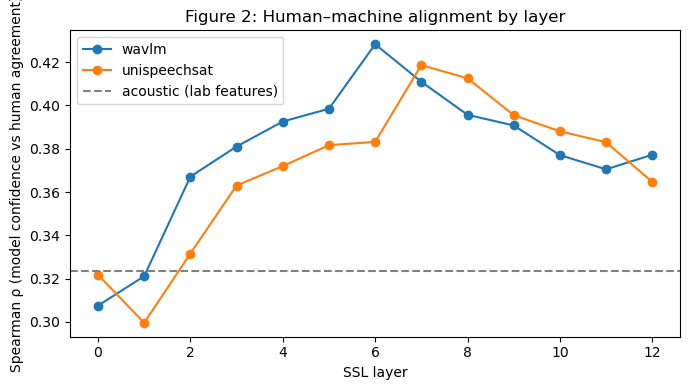

In [3]:
# this gives one of our main objective results: how well does model 
# confidence align with human agreement, investiaged across each layer?
# we observe moderate correalation between 0.3 to 0.5, being strongest for middle layers
rows = []
for (system, layer), g in preds.groupby(["system", "layer"]):
    rho, p = spearmanr(g["p_true"], g["human_agreement"])
    rows.append({"system": system, "layer": layer, "rho": rho, "p": p})
align = pd.DataFrame(rows)
print(align.round(3))
align.to_csv("../results/alignment_by_layer.csv", index=False)

plt.figure(figsize=(7, 4))
for system in ["wavlm", "unispeechsat"]:
    a = align[align.system == system]
    plt.plot(a.layer, a.rho, marker="o", label=system)
plt.axhline(align[align.system == "acoustic"].rho.iloc[0], color="grey",
            linestyle="--", label="acoustic (lab features)")
plt.xlabel("SSL layer"); plt.ylabel("Spearman ρ (model confidence vs human agreement)")
plt.title("Figure 2: Human–machine alignment by layer"); plt.legend()
plt.tight_layout(); plt.savefig("../results/figures/fig2_layer_alignment.png", dpi=200); plt.show()

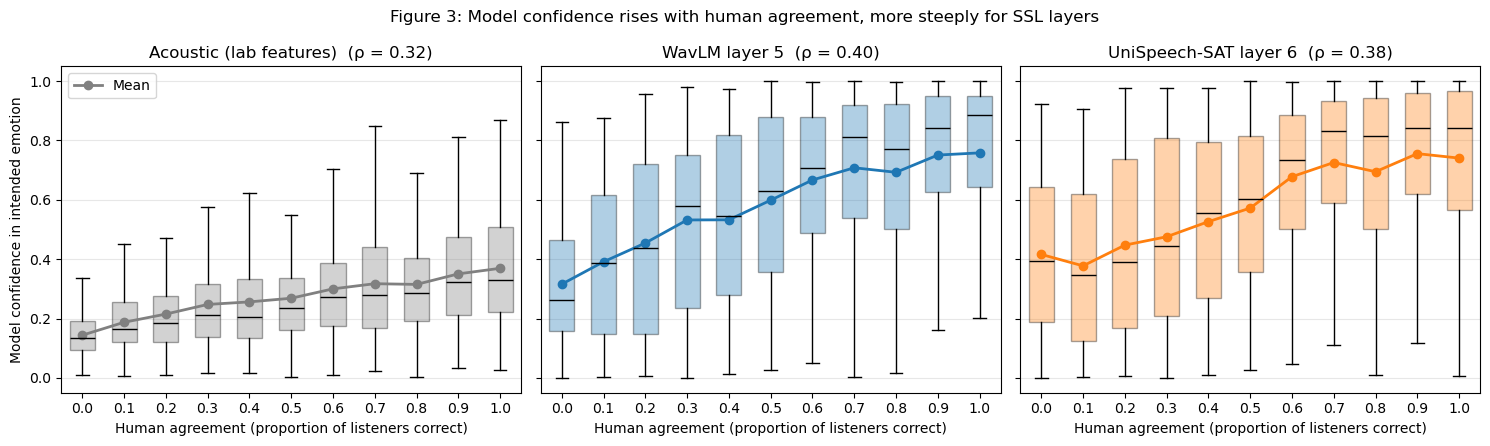

In [4]:
# ---- Figure 3: distribution of model confidence at each human-agreement level ----
picks = [("acoustic", -1, "Acoustic (lab features)", "grey"),
         ("wavlm", 5, "WavLM layer 5", "tab:blue"),
         ("unispeechsat", 6, "UniSpeech-SAT layer 6", "tab:orange")]
levels = np.round(np.arange(0, 1.01, 0.1), 1)          # human agreement comes in 0.1 steps

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (system, layer, title, colour) in zip(axes, picks):
    g = preds[(preds.system == system) & (preds.layer == layer)]
    data = [g.p_true[g.human_agreement.round(1) == lv] for lv in levels]

    # one box per agreement level: middle line = median, box = middle 50% of clips
    ax.boxplot(data, positions=range(len(levels)), widths=0.6, showfliers=False,
               patch_artist=True, boxprops=dict(facecolor=colour, alpha=0.35),
               medianprops=dict(color="black"))
    ax.plot(range(len(levels)), [d.mean() for d in data], color=colour, marker="o", lw=2, label="Mean")

    rho = spearmanr(g.p_true, g.human_agreement)[0]
    ax.set_title(f"{title}  (ρ = {rho:.2f})")
    ax.set_xticks(range(len(levels))); ax.set_xticklabels(levels)
    ax.set_xlabel("Human agreement (proportion of listeners correct)")
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Model confidence in intended emotion")
axes[0].legend(loc="upper left")
plt.suptitle("Figure 3: Model confidence rises with human agreement, more steeply for SSL layers")
plt.tight_layout(); plt.savefig("../results/figures/fig3_confidence_by_agreement.png", dpi=200); plt.show()

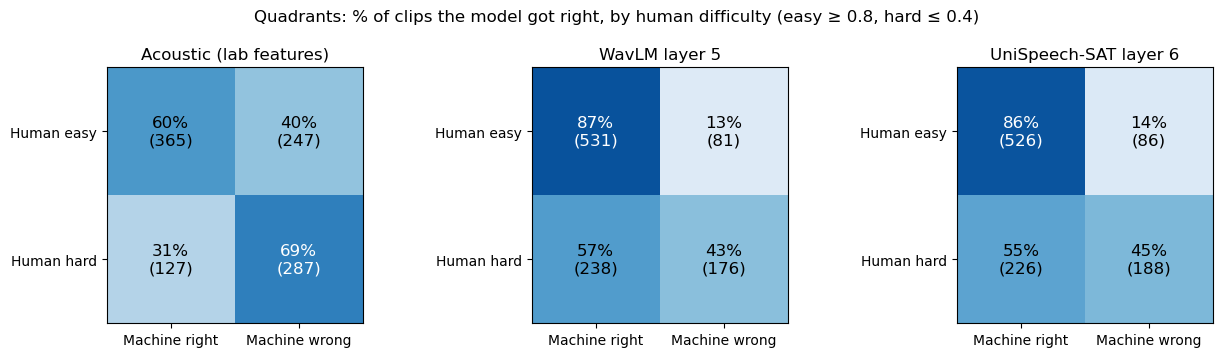

In [5]:
# ---- Quadrants: human easy/hard x machine right/wrong (row percentages) ----
def quadrant(row):
    if row.human_agreement >= 0.8:   human = "Human easy"
    elif row.human_agreement <= 0.4: human = "Human hard"
    else:                            return None          # middle clips left out
    return human, ("Machine right" if row.correct == 1 else "Machine wrong")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (system, layer, title, _) in zip(axes, picks):
    g = preds[(preds.system == system) & (preds.layer == layer)].copy()
    g["quadrant"] = g.apply(quadrant, axis=1)
    g = g.dropna(subset=["quadrant"])
    g[["human", "machine"]] = pd.DataFrame(g.quadrant.tolist(), index=g.index)

    counts = pd.crosstab(g.human, g.machine)                         # 2x2 counts
    pct = pd.crosstab(g.human, g.machine, normalize="index") * 100   # % within each human row

    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{pct.iloc[i, j]:.0f}%\n({counts.iloc[i, j]})",
                    ha="center", va="center", fontsize=12,
                    color="white" if pct.iloc[i, j] > 60 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(pct.columns)
    ax.set_yticks([0, 1]); ax.set_yticklabels(pct.index)
    ax.set_title(title)

    # save the two interesting quadrants for case studies
    g[((g.human == "Human easy") & (g.machine == "Machine wrong")) |
      ((g.human == "Human hard") & (g.machine == "Machine right"))] \
        .to_csv(f"../results/cases_{system}_{layer}.csv", index=False)

plt.suptitle("Quadrants: % of clips the model got right, by human difficulty (easy ≥ 0.8, hard ≤ 0.4)")
plt.tight_layout(); plt.savefig("../results/figures/quadrants.png", dpi=200); plt.show()

Acoustic (lab features) top confusions: [('sad->calm', np.float64(0.21)), ('sad->neutral', np.float64(0.21)), ('happy->surprised', np.float64(0.17))]
WavLM layer 5 top confusions: [('sad->calm', np.float64(0.18)), ('neutral->calm', np.float64(0.15)), ('calm->sad', np.float64(0.11))]
UniSpeech-SAT layer 6 top confusions: [('sad->calm', np.float64(0.13)), ('calm->sad', np.float64(0.13)), ('sad->fearful', np.float64(0.1))]


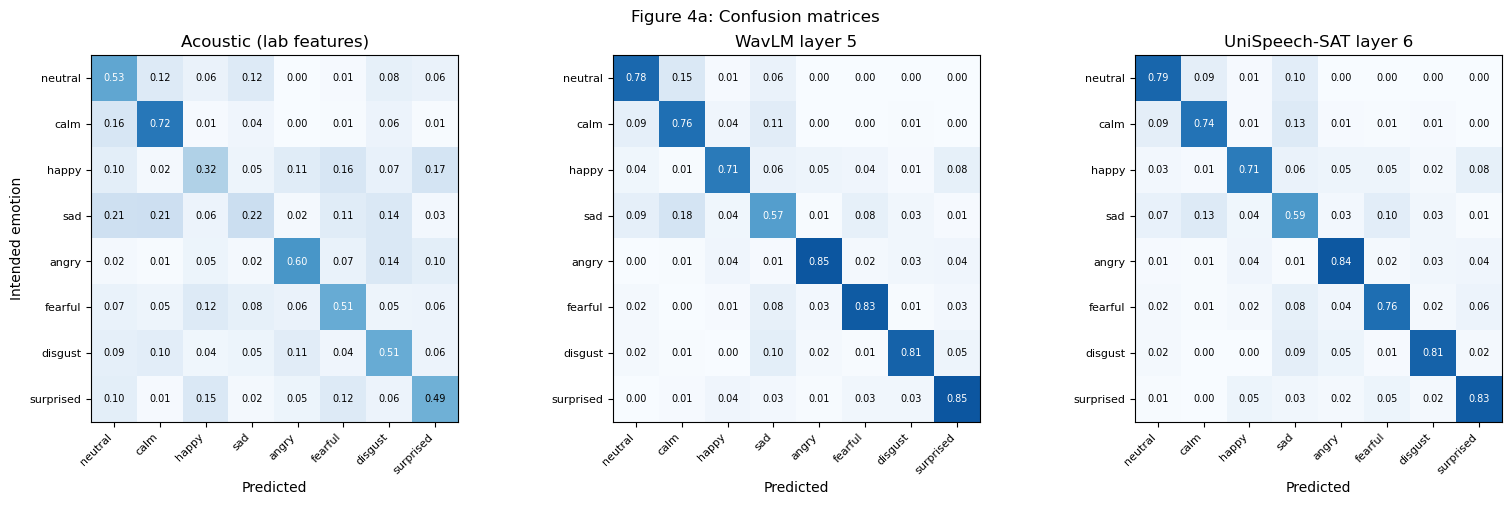

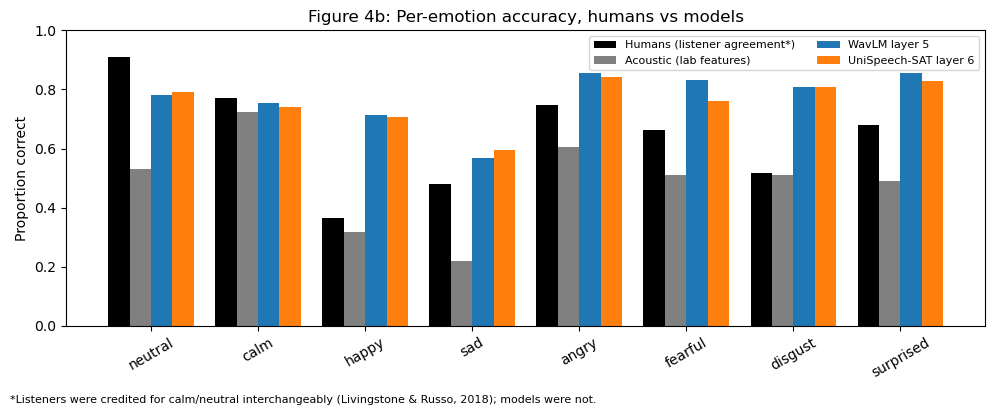

Acoustic (lab features): ρ with human per-emotion accuracy = 0.83
WavLM layer 5: ρ with human per-emotion accuracy = 0.40
UniSpeech-SAT layer 6: ρ with human per-emotion accuracy = 0.48


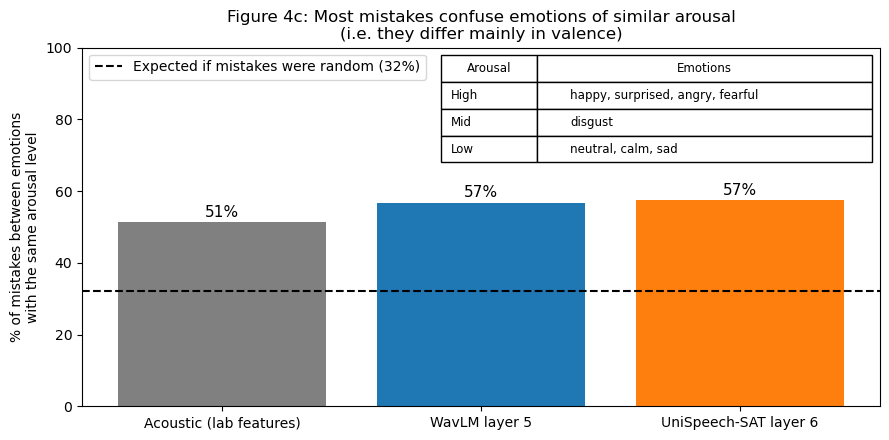

In [6]:
# ============================================================
# Figure 4: Which emotions are confused?
# 4a: confusion matrices (models only)
# 4b: per-emotion accuracy, humans vs models
# 4c: are mistakes mostly between emotions of the SAME arousal?
# ============================================================
from sklearn.metrics import confusion_matrix
emotions = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

# ---- Figure 4a: confusion matrices (rows = intended emotion, columns = prediction) ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
recall = {}
for ax, (system, layer, title, colour) in zip(axes, picks):
    g = preds[(preds.system == system) & (preds.layer == layer)]
    cm = confusion_matrix(g.emotion, g.pred, labels=emotions, normalize="true")   # rows sum to 1
    recall[title] = (np.diag(cm), colour)                                          # per-emotion accuracy
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(8):
        for j in range(8):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(8)); ax.set_xticklabels(emotions, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(8)); ax.set_yticklabels(emotions, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_title(title)

    # 3 biggest confusions, for the report text
    off = sorted([(cm[i, j], emotions[i], emotions[j]) for i in range(8) for j in range(8) if i != j], reverse=True)[:3]
    print(title, "top confusions:", [(f"{a}->{b}", round(v, 2)) for v, a, b in off])
axes[0].set_ylabel("Intended emotion")
plt.suptitle("Figure 4a: Confusion matrices")
plt.tight_layout(); plt.savefig("../results/figures/fig4a_confusions.png", dpi=200); plt.show()

# ---- Figure 4b: per-emotion accuracy, humans vs models ----
human_acc = meta.groupby("emotion").human_agreement.mean().reindex(emotions)
x, w = np.arange(8), 0.2
plt.figure(figsize=(10, 4))
plt.bar(x - 1.5*w, human_acc, w, color="black", label="Humans (listener agreement*)")
for k, (title, (r, colour)) in enumerate(recall.items()):
    plt.bar(x + (k - 0.5)*w, r, w, color=colour, label=title)
plt.xticks(x, emotions, rotation=30); plt.ylim(0, 1); plt.ylabel("Proportion correct")
plt.title("Figure 4b: Per-emotion accuracy, humans vs models")
plt.figtext(0.01, -0.02, "*Listeners were credited for calm/neutral interchangeably (Livingstone & Russo, 2018); models were not.",
            fontsize=8, ha="left")
plt.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig("../results/figures/fig4b_per_emotion.png", dpi=200, bbox_inches="tight"); plt.show()

# do models find the same EMOTIONS hard as humans? (8 points: indicative only)
for title, (r, _) in recall.items():
    print(f"{title}: ρ with human per-emotion accuracy = {spearmanr(r, human_acc)[0]:.2f}")

# ---- Figure 4c: do mistakes stay within the same arousal level? ----
# arousal groups (Russell's circumplex model; disgust treated as moderate arousal)
arousal = {"neutral": "low", "calm": "low", "sad": "low", "disgust": "mid",
           "happy": "high", "surprised": "high", "angry": "high", "fearful": "high"}
# if mistakes were random, this share of them would land in the same arousal group
pairs = [(a, b) for a in emotions for b in emotions if a != b]
chance = np.mean([arousal[a] == arousal[b] for a, b in pairs])

labels, same, colours = [], [], []
for system, layer, title, colour in picks:
    err = preds[(preds.system == system) & (preds.layer == layer) & (preds.emotion != preds.pred)]
    same.append(100 * (err.emotion.map(arousal) == err.pred.map(arousal)).mean())
    labels.append(title); colours.append(colour)

plt.figure(figsize=(9, 4.5))
bars = plt.bar(labels, same, color=colours)
plt.axhline(100 * chance, color="black", linestyle="--", label=f"Expected if mistakes were random ({chance:.0%})")
for b, v in zip(bars, same):
    plt.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}%", ha="center", fontsize=11)


# key: which emotions belong to each arousal level (small table, top-right)
key = plt.table(cellText=[["High", "happy, surprised, angry, fearful"],
                          ["Mid",  "disgust"],
                          ["Low",  "neutral, calm, sad"]],
                colLabels=["Arousal", "Emotions"],
                cellLoc="left", colWidths=[0.12, 0.42],
                bbox=[0.45, 0.68, 0.54, 0.3])          # [x, y, width, height] in axes fraction
key.auto_set_font_size(False); key.set_fontsize(8.5)

plt.ylim(0, 100); plt.ylabel("% of mistakes between emotions\nwith the same arousal level")
plt.title("Figure 4c: Most mistakes confuse emotions of similar arousal\n(i.e. they differ mainly in valence)")
plt.legend(loc="upper left"); plt.tight_layout()
plt.savefig("../results/figures/fig4c_arousal_errors.png", dpi=200); plt.show()

                   measure   normal   strong  difference    p
0          human_agreement    0.533    0.674       0.141  0.0
1  Acoustic (lab features)    0.252    0.343       0.091  0.0
2            WavLM layer 5    0.575    0.703       0.129  0.0
3    UniSpeech-SAT layer 6    0.578    0.697       0.118  0.0
4                  f0_mean  198.532  250.045      51.513  0.0
5              int_mean_db  -48.917  -41.758       7.159  0.0


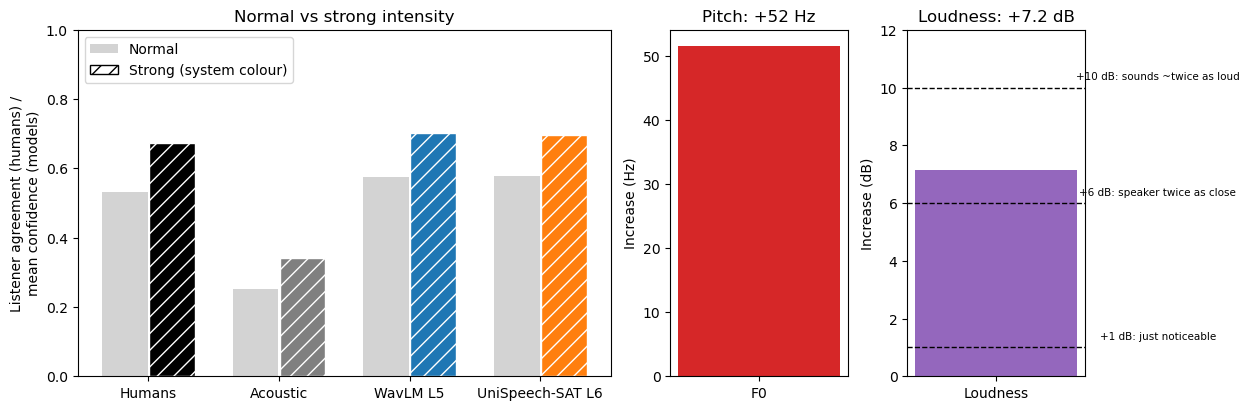

In [7]:
# ============================================================
# Figure 5: Are strong expressions easier for humans and models?
# Each normal clip is paired with its strong twin (same actor, emotion,
# sentence, repetition). Neutral has no strong version, so it is left out.
# ============================================================
from scipy.stats import wilcoxon

acou = pd.read_csv("../results/acoustic_features.csv")
pair_key = ["actor", "emotion", "statement", "repetition"]

# one table: metadata + acoustic cues + each system's confidence as a column
data = meta.merge(acou[["filename", "f0_mean", "int_mean_db"]], on="filename")
for system, layer, title, _ in picks:
    conf = preds[(preds.system == system) & (preds.layer == layer)][["filename", "p_true"]]
    data = data.merge(conf.rename(columns={"p_true": title}), on="filename")
data = data[data.emotion != "neutral"]

# normal vs strong for each measure (paired Wilcoxon test)
columns = ["human_agreement"] + [t for _, _, t, _ in picks] + ["f0_mean", "int_mean_db"]
rows = []
for col in columns:
    wide = data.pivot_table(index=pair_key, columns="intensity", values=col)
    rows.append({"measure": col, "normal": wide.normal.mean(), "strong": wide.strong.mean(),
                 "difference": (wide.strong - wide.normal).mean(),
                 "p": wilcoxon(wide.strong, wide.normal)[1]})
intensity = pd.DataFrame(rows)
print(intensity.round(3))
intensity.to_csv("../results/intensity_effect.csv", index=False)

# ---- plot ----
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 1, 1]})

# left: humans vs models, normal vs strong
top = intensity.iloc[:4]
names = ["Humans", "Acoustic", "WavLM L5", "UniSpeech-SAT L6"]
colours = ["black", "grey", "tab:blue", "tab:orange"]
x = np.arange(4)
axes[0].bar(x - 0.18, top.normal, 0.35, color="lightgrey")
axes[0].bar(x + 0.18, top.strong, 0.35, color=colours, hatch="//", edgecolor="white")
axes[0].set_xticks(x); axes[0].set_xticklabels(names); axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Listener agreement (humans) /\nmean confidence (models)")
axes[0].set_title("Normal vs strong intensity")
axes[0].legend(handles=[Patch(facecolor="lightgrey", label="Normal"),
                        Patch(facecolor="white", edgecolor="black", hatch="//", label="Strong (system colour)")],
               loc="upper left")

# middle and right: acoustic change, each on its own scale
f0_up, db_up = intensity.difference.iloc[4], intensity.difference.iloc[5]
axes[1].bar(["F0"], [f0_up], color="tab:red", width=0.5)
axes[1].set_ylabel("Increase (Hz)"); axes[1].set_title(f"Pitch: +{f0_up:.0f} Hz")
# loudness change with familiar reference changes
axes[2].bar(["Loudness"], [db_up], color="tab:purple", width=0.5)
refs = [(1, "+1 dB: just noticeable"),
        (6, "+6 dB: speaker twice as close"),
        (10, "+10 dB: sounds ~twice as loud")]
for level, text in refs:
    axes[2].axhline(level, color="black", linestyle="--", lw=1)
    axes[2].text(0.5, level + 0.2, text, fontsize=7.5, ha="center", va="bottom")
axes[2].set_ylim(0, 12)
axes[2].set_ylabel("Increase (dB)"); axes[2].set_title(f"Loudness: +{db_up:.1f} dB")
plt.savefig("../results/figures/fig5_intensity.png", dpi=200, bbox_inches="tight")

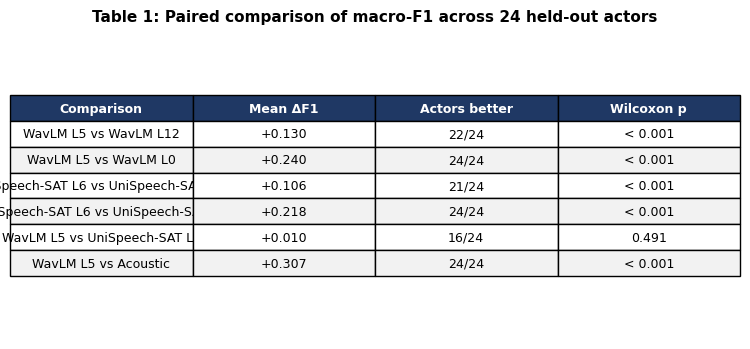

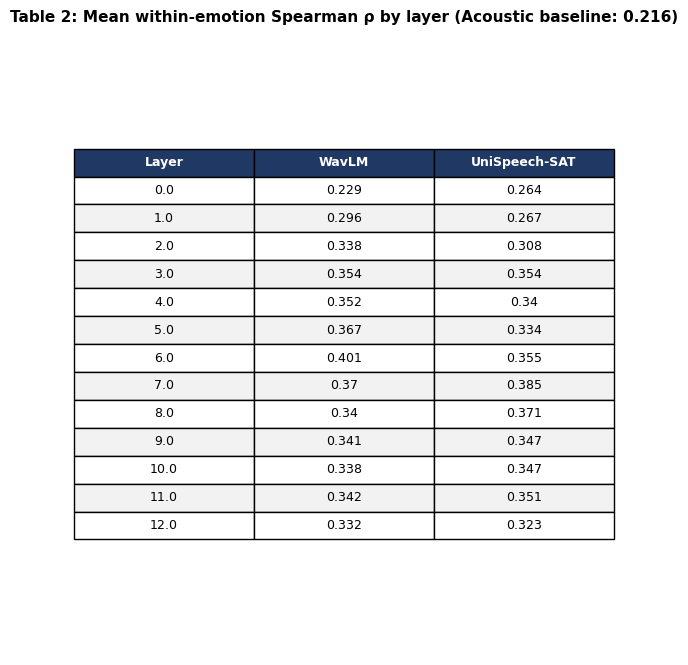

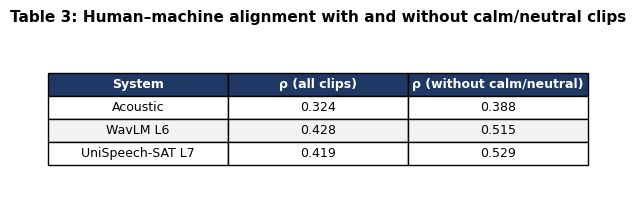

In [8]:
# ============================================================
# Robustness checks -> three report-ready tables
# Table 1: paired layer comparisons across the same 24 actors
# Table 2: alignment inside each emotion (not just "happy is hard")
# Table 3: alignment without calm/neutral (listeners were credited for
#          calm<->neutral confusions; the models were not)
# (95% CIs for overall alignment are shown in Figure 2.)
# ============================================================
from sklearn.metrics import f1_score
from scipy.stats import wilcoxon

names = {"wavlm": "WavLM", "unispeechsat": "UniSpeech-SAT", "acoustic": "Acoustic"}
def label(system, layer):
    return names[system] if layer == -1 else f"{names[system]} L{layer}"
def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

def save_table(df, title, filename):
    """Save a table as CSV and as a clean PNG for the report, and show it."""
    df.to_csv(f"../results/{filename}.csv", index=False)
    fig, ax = plt.subplots(figsize=(1.9 * len(df.columns), 0.45 * len(df) + 0.9))
    ax.axis("off")
    t = ax.table(cellText=df.values, colLabels=df.columns, cellLoc="center", loc="center")
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.4)
    for (r, c), cell in t.get_celld().items():
        if r == 0:
            cell.set_facecolor("#1f3864"); cell.set_text_props(color="white", weight="bold")
        elif r % 2 == 0:
            cell.set_facecolor("#f2f2f2")
    ax.set_title(title, fontsize=11, weight="bold", pad=8)
    plt.tight_layout(); plt.savefig(f"../results/figures/{filename}.png", dpi=200, bbox_inches="tight"); plt.show()

# per-actor macro-F1 for every system/layer
actor_f1 = (preds.groupby(["system", "layer", "actor"])
                 .apply(lambda g: f1_score(g.emotion, g.pred, average="macro"))
                 .rename("f1").reset_index())
def f1_of(system, layer):
    return actor_f1[(actor_f1.system == system) & (actor_f1.layer == layer)].set_index("actor").f1

# ---------- Table 1: paired layer comparisons ----------
rows = []
for (s1, l1), (s2, l2) in [(("wavlm", 5), ("wavlm", 12)), (("wavlm", 5), ("wavlm", 0)),
                           (("unispeechsat", 6), ("unispeechsat", 12)), (("unispeechsat", 6), ("unispeechsat", 0)),
                           (("wavlm", 5), ("unispeechsat", 6)), (("wavlm", 5), ("acoustic", -1))]:
    a, b = f1_of(s1, l1), f1_of(s2, l2)
    rows.append({"Comparison": f"{label(s1, l1)} vs {label(s2, l2)}",
                 "Mean ΔF1": f"{(a - b).mean():+.3f}",
                 "Actors better": f"{(a > b).sum()}/24",
                 "Wilcoxon p": fmt_p(wilcoxon(a, b)[1])})
table1 = pd.DataFrame(rows)
save_table(table1, "Table 1: Paired comparison of macro-F1 across 24 held-out actors", "table1_paired_layers")

# ---------- Table 2: alignment inside each emotion ----------
rows = []
for (system, layer), g in preds.groupby(["system", "layer"]):
    rho = np.mean([spearmanr(e.p_true, e.human_agreement)[0] for _, e in g.groupby("emotion")])
    rows.append({"system": system, "layer": layer, "rho": rho})
within = pd.DataFrame(rows)
table2 = (within[within.system != "acoustic"]
          .pivot(index="layer", columns="system", values="rho").round(3)
          .rename(columns=names).reset_index().rename(columns={"layer": "Layer"}))
table2 = table2[["Layer", "WavLM", "UniSpeech-SAT"]]
acoustic_within = within[within.system == "acoustic"].rho.iloc[0]
save_table(table2, f"Table 2: Mean within-emotion Spearman ρ by layer (Acoustic baseline: {acoustic_within:.3f})",
           "table2_within_emotion")

# ---------- Table 3: alignment without calm and neutral ----------
rows = []
for system, layer in [("acoustic", -1), ("wavlm", 6), ("unispeechsat", 7)]:
    g = preds[(preds.system == system) & (preds.layer == layer)]
    rest = g[~g.emotion.isin(["calm", "neutral"])]
    rows.append({"System": label(system, layer),
                 "ρ (all clips)": f"{spearmanr(g.p_true, g.human_agreement)[0]:.3f}",
                 "ρ (without calm/neutral)": f"{spearmanr(rest.p_true, rest.human_agreement)[0]:.3f}"})
table3 = pd.DataFrame(rows)
save_table(table3, "Table 3: Human–machine alignment with and without calm/neutral clips", "table3_calm_neutral")

In [9]:
# ---- Case-study candidates: both SSL models agree, humans disagree ----
w = preds[(preds.system == "wavlm") & (preds.layer == 5)].set_index("filename")
u = preds[(preds.system == "unispeechsat") & (preds.layer == 6)].set_index("filename")
cases = pd.DataFrame({"Emotion": w.emotion, "Actor": w.actor, "Intensity": w.intensity,
                      "Listener agreement": w.human_agreement,
                      "WavLM pred": w.pred, "WavLM conf": w.p_true.round(2),
                      "UniSAT pred": u.pred, "UniSAT conf": u.p_true.round(2)})

easy_wrong = cases[(cases["Listener agreement"] >= 0.9) & (cases["WavLM conf"] < 0.2) & (cases["UniSAT conf"] < 0.2)]
hard_right = cases[(cases["Listener agreement"] <= 0.3) & (cases["WavLM conf"] > 0.8) & (cases["UniSAT conf"] > 0.8)]

print(f"Listeners easy, both models confidently wrong: {len(easy_wrong)} clips")
display(easy_wrong.sort_values("WavLM conf").head(8))
print(f"\nListeners hard, both models confidently right: {len(hard_right)} clips")
display(hard_right.sort_values("Listener agreement").head(8))

easy_wrong.to_csv("../results/cases_easy_wrong.csv"); hard_right.to_csv("../results/cases_hard_right.csv")

Listeners easy, both models confidently wrong: 13 clips


,Emotion,Actor,Intensity,Listener agreement,WavLM pred,WavLM conf,UniSAT pred,UniSAT conf
filename,,,,,,,,
03-01-02-01-02-02-13.wav,calm,13,normal,0.9,sad,0.00,sad,0.01
03-01-02-02-02-02-13.wav,calm,13,strong,0.9,neutral,0.00,neutral,0.01
03-01-02-02-01-02-13.wav,calm,13,strong,1.0,neutral,0.01,neutral,0.01
03-01-02-02-01-01-13.wav,calm,13,strong,1.0,sad,0.01,sad,0.02
03-01-02-02-02-01-13.wav,calm,13,strong,1.0,sad,0.01,neutral,0.01
03-01-02-01-01-02-13.wav,calm,13,normal,1.0,neutral,0.02,neutral,0.03
03-01-02-01-02-01-13.wav,calm,13,normal,1.0,sad,0.05,sad,0.07
03-01-02-02-02-02-17.wav,calm,17,strong,0.9,sad,0.08,sad,0.13



Listeners hard, both models confidently right: 31 clips


,Emotion,Actor,Intensity,Listener agreement,WavLM pred,WavLM conf,UniSAT pred,UniSAT conf
filename,,,,,,,,
03-01-03-01-01-02-10.wav,happy,10,normal,0.0,happy,0.86,happy,0.86
03-01-03-01-01-02-21.wav,happy,21,normal,0.0,happy,0.82,happy,0.92
03-01-07-02-01-02-10.wav,disgust,10,strong,0.1,disgust,0.84,disgust,0.87
03-01-07-01-02-02-01.wav,disgust,1,normal,0.1,disgust,0.87,disgust,0.90
03-01-03-01-02-02-21.wav,happy,21,normal,0.1,happy,0.83,happy,0.86
03-01-03-01-02-02-07.wav,happy,7,normal,0.2,happy,0.81,happy,0.85
03-01-07-02-01-01-10.wav,disgust,10,strong,0.2,disgust,0.84,disgust,0.97
03-01-03-02-02-01-01.wav,happy,1,strong,0.2,happy,0.91,happy,0.86
